# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `gt`: Ground truth

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
run = "24"

# data
fwd = dm.load(sub, "fwd", desc="inv")
ave = dm.load(sub, "ave", run=run)
ncov = dm.load(sub, "cov", run=run)
eig = dm.load(sub, "eig")
gold = dm.load(sub, "gold", run=run)

# crop
tmin = -0.05
tmax = 0.15

## 🧬 - Data Processing
Estimate regularization parameter

In [2]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
lambda2 = 1.0 / (snr.max()**2)

print(f"Estimated SNR: {snr.max():.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

# cap the regularization parameter. Smaller values don't regularize anymore.
lambda2 = max(0.01, lambda2)

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None
    Using tolerance 4.1e-15 (2.2e-16 eps * 203 dim * 0.09  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)
Estimated SNR: 25.619
Estimated lambda2: 0.002


Apply inverse solver

In [3]:
# crop
data = ave.copy().crop(tmin=tmin, tmax=tmax)
ground = gold.copy().crop(tmin=tmin, tmax=tmax)

#ncov = mne.cov.make_ad_hoc_cov(ave.info)
#lambda2 = 0.01

# --------------------------------
# Methods implemented in MindMap
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# --------------------------------

# # mindmap's CSET
# inv = mm.analysis.inverse.CSET(
#     forward = fwd,
#     noise_cov = ncov,
#     depth = 0.8,
#     eigenvectors = eig["vec"],
# )

# cset = inv.solve(data, lambda2 = 0.1)


# mindmap's wCSET
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0,
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 0.8,
)

wcset = inv.solve(data, 0.01)

# # mindmap's MCE
# inv = mm.analysis.inverse.MCE(
#     forward = fwd,
#     noise_cov = ncov,
#     depth = 0.8,
# )

# mce = inv.solve(data, lambda2 = 0.1)


# -----------------------------------
# Methods implemented in MNE-Python
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# -----------------------------------


inv_mne = mne.minimum_norm.make_inverse_operator(
    info = data.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

# MNE-python's sLORETA
sloreta = mne.minimum_norm.apply_inverse(
    data,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

# MNE-python's dSPM
dspm = mne.minimum_norm.apply_inverse(
    data,
    inv_mne,
    lambda2,
    method = "dSPM",
)

Computing inverse operator with 203 channels.
    203 out of 203 channels remain after picking
Selected 203 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 4.1e-15 (2.2e-16 eps * 203 dim * 0.09  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 2.55573
    scaling factor to adjust the trace = 2.7689e+22 (nchan = 203 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 20
    C

Evaluate reconstructions

In [4]:
# instanciate variables
metrics = mm.metric.MetricSuite(f"Example {sub}")
times = ground.times
recons = {
    #"cset": cset,
    "wcset": wcset,
    "sloreta": sloreta,
    "dspm": dspm,
    #"mce": mce,
}

# ------------------------------
# Compute bunch of metrics and
# add them to the Suite.
# ------------------------------

for name, sol in recons.items():
    # correlation
    corr = mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson")
    metrics.register(name, "correlation", corr, times=times)

    # cosine
    cosine = mm.analysis.inverse.compute_stc_cosine(ground, sol, mode="spatial", absolute=False)
    metrics.register(name, "cosine", cosine, times=times)

    # precision-recall curve at half rising phase
    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)    # half rising phase
    activity_mask = ground.data[:,hrp] > 0
    estimated = sol.data[:,hrp]
    curves = mm.core.calc_performance_curves(activity_mask, estimated)
    precision, recall = curves["pr"]["precision"], curves["pr"]["recall"]
    metrics.register(name, "precision_hrp", precision, recall=recall)

    # precision-recall curve at peak phase
    pp  = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)      # peak phase
    activity_mask = ground.data[:,pp] > 0
    estimated = sol.data[:,pp]
    curves = mm.core.calc_performance_curves(activity_mask, estimated)
    precision, recall = curves["pr"]["precision"], curves["pr"]["recall"]
    metrics.register(name, "precision_pp", precision, recall=recall)

## 📊 - Visualization

Measurements - timeseries

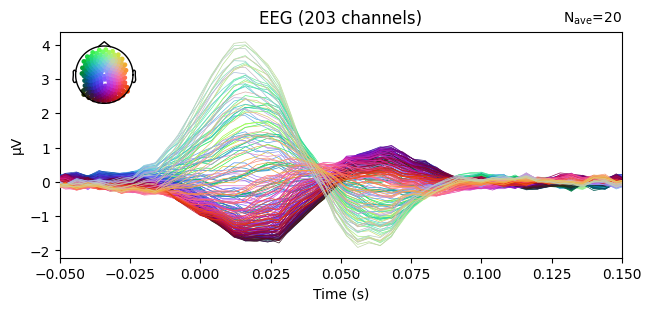

In [5]:
_ = ave.plot(xlim=(tmin, tmax))



Measurements - topographies

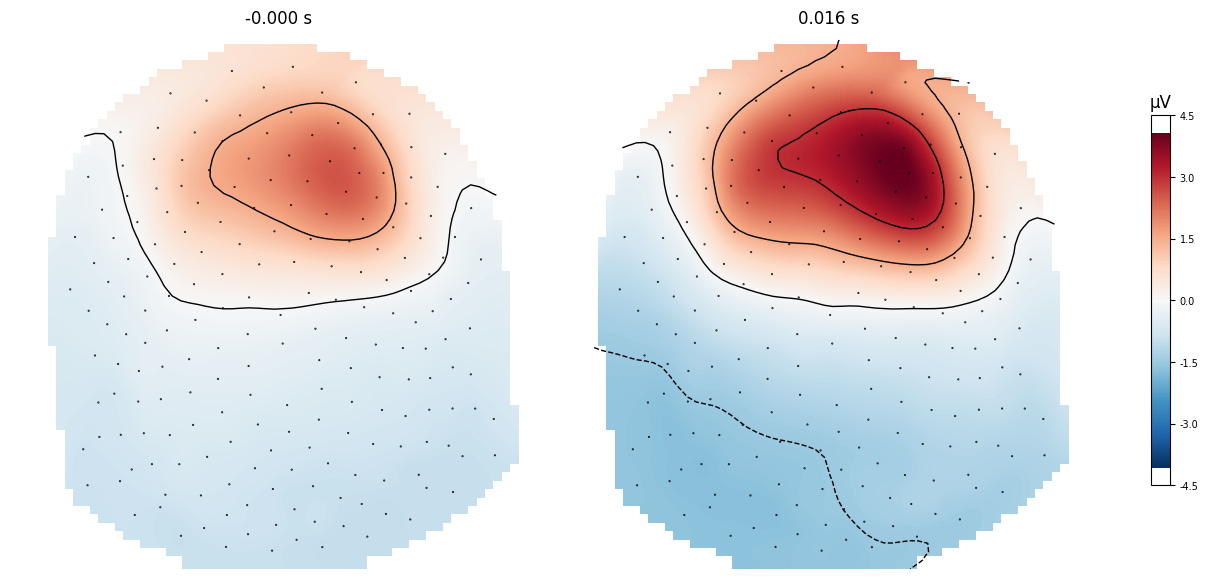

In [6]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [7]:
tmin, tmax = -0.025, 0.1
mm.viz.plot_brain_activity(
    source_space = fwd["src"],
    functionals = [wcset.copy().crop(tmin, tmax), sloreta.copy().crop(tmin, tmax), ground.copy().crop(tmin, tmax)],
    title = ["wcset", "sloreta",  "gold"],
    func_params = {"normalize": "max", "absolute": True}
).show()

/home/nino/Code/mindmap/mindmap/viz/vista.py:85: UserWarning: Inconsistent time vectors detected across meshes. Using the first available.
  warnings.warn("Inconsistent time vectors detected across meshes. Using the first available.")


Widget(value='<iframe src="http://localhost:42769/index.html?ui=P_0x7d83b58225d0_0&reconnect=auto" class="pyvi…

In [7]:
mm.viz.plot_brain_activity(fwd["src"], ground, func_params={"normalize":"max", "absolute": True}).show()

Widget(value='<iframe src="http://localhost:41823/index.html?ui=P_0x7a7c08773cd0_1&reconnect=auto" class="pyvi…

In [27]:
mm.viz.plot_spectrum(eig["vec"].T @ wcset.data, times = wcset.times).show()

Measured metrics.

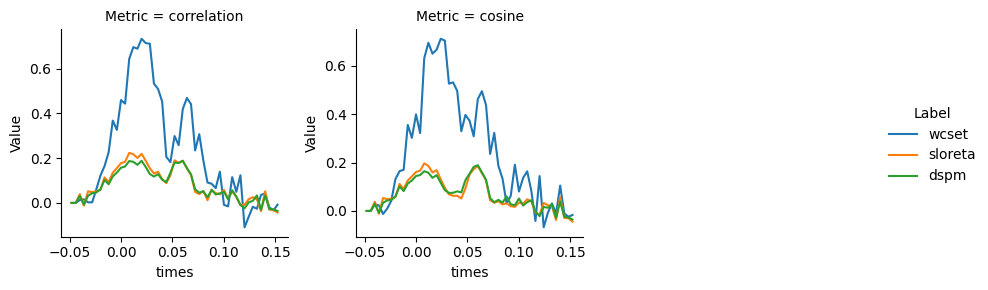

In [5]:
g = metrics.plot(
    metrics = ["correlation", "cosine"],
    labels = ["cset", "sloreta", "wcset", "dspm"],
    coord = "times",
)


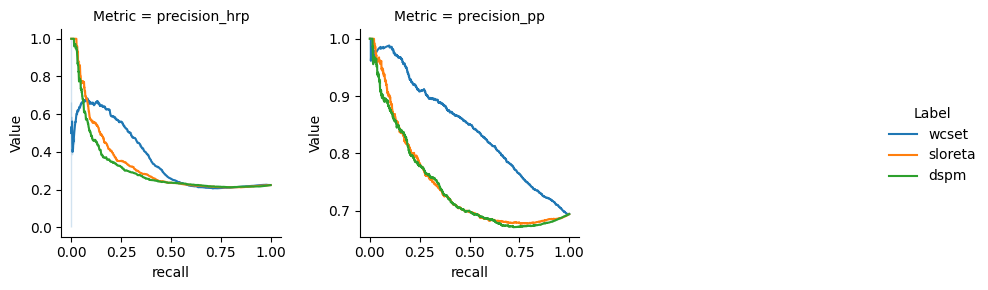

In [6]:
g = metrics.plot(
    metrics = ["precision_hrp", "precision_pp"],
    labels = ["sloreta", "wcset", "dspm"],
    coord = "recall",
)

In [ ]:
import mindmap as mm
from joblib import Parallel, delayed
from tqdm import tqdm
from pathlib import Path


# 1. Define paths and methods
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
AVE_DIR = dm.roots["mm"]/sub/"ave"
methods = ["dspm", "sloreta", "cset", "wcset"]

# 2. Gather all files
all_files = list(AVE_DIR.glob("*.fif"))
total_dataset_size = len(all_files)

# 3. Filter out what is already done
print("Checking disk for existing results...")
files_ave = mm.analysis.inverse.filter_remaining_files(all_files, methods)

already_done = total_dataset_size - len(files_ave)
print(f"Dataset Status: {already_done}/{total_dataset_size} files already completed.")
print(f"Files left to process: {len(files_ave)}")

if len(files_ave) == 0:
    print("All files processed! Exiting.")
    exit()

# Generate matching covariance file paths
files_cov = [Path(str(f).replace("ave", "cov")) for f in files_ave]

for fcov in files_cov:
    if not fcov.exists():
        raise FileNotFoundError(f"Missing expected covariance file: {fcov}")

# 4. Load static variables
forward = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")

# 5. Initialize process factory
process_one_file = mm.analysis.inverse.make_process_sample(
    methods = methods,
    forward = forward,
    eig = eig,
    crop = [-0.01, 0.15],
)

# 6. Launch Parallel Processing with a tqdm Progress Bar
print(f"Spawning parallele workers across available cores...")

results = Parallel(n_jobs=1)(
    delayed(process_one_file)(fave, fcov) 
    for fave, fcov in tqdm(
        zip(files_ave, files_cov),
        total=len(files_ave),
        desc="Reconstructing Sources",
    )
)

print("\nProcessing cycle complete!")

Checking disk for existing results...
Dataset Status: 0/0 files already completed.
Files left to process: 0
All files processed! Exiting.
Spawning parallele workers across available cores...


Reconstructing Sources: 0it [00:00, ?it/s]


Processing cycle complete!


: 